In [35]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


In [36]:
# Create Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):
    """
    Scale price using a linear trend on smoothed log-variance.
    """

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility (safe sqrt)
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import target series and detrend series with HP filter + linear trend of the volatility scaling

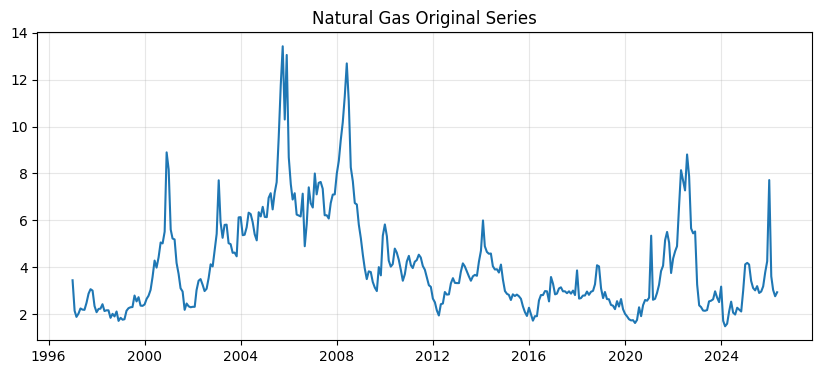

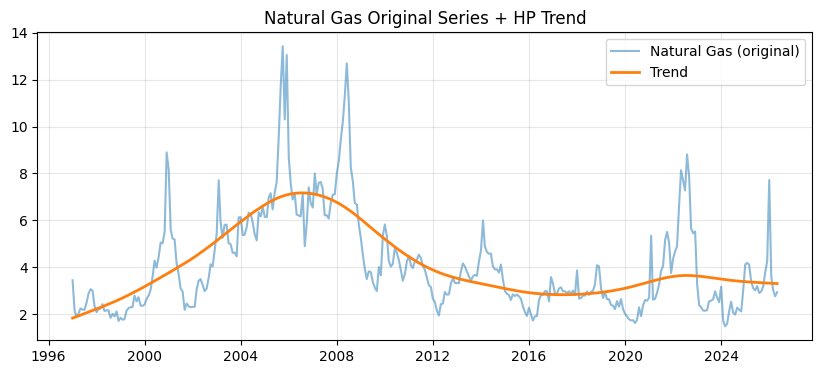

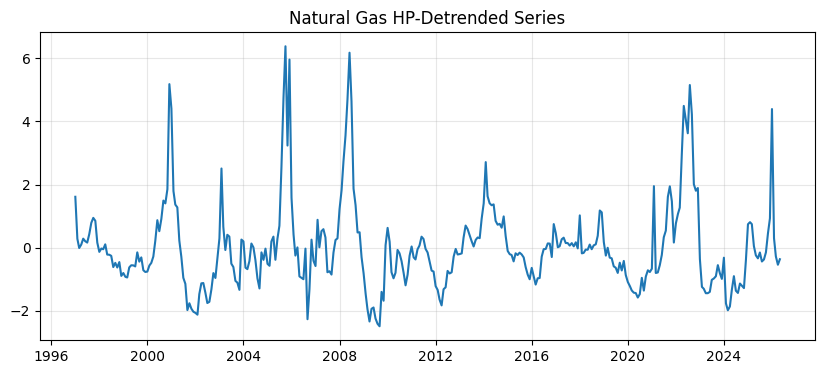

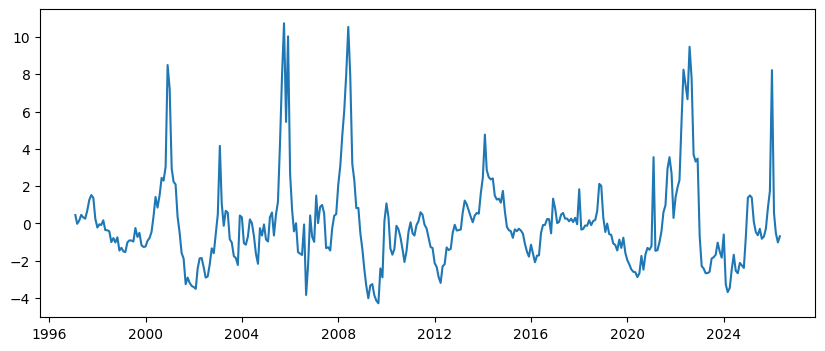

In [37]:
# -------------------------
# DATA
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

df_ngas["gas_cycle"] = cycle
df_ngas["gas_trend"] = trend


gas_diff = (df_ngas["gas_cycle"]).diff().dropna()
gas_sigma = linear_vol_scale(gas_diff)


df_ngas["gas_scaled_cycle"]= df_ngas["gas_cycle"]/gas_sigma

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"])
plt.title("Natural Gas Original Series")
plt.grid(alpha=0.3)
plt.show()


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"], label="Natural Gas (original)", alpha=0.5)
plt.plot(df_ngas.index, df_ngas["gas_trend"], label="Trend", linewidth=2)
plt.title("Natural Gas Original Series + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_cycle"])
plt.title("Natural Gas HP-Detrended Series")
plt.grid(True, alpha=0.3)
plt.show()

# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_scaled_cycle"])
#plt.ylabel("HP-detrended price scaled \n by the linear trend \n of the volatility", fontsize=18)
# Increase tick-label font size (axis scales)
#plt.tick_params(axis="both", labelsize=14)
plt.show()


### Extract Data for Exogeous Variables

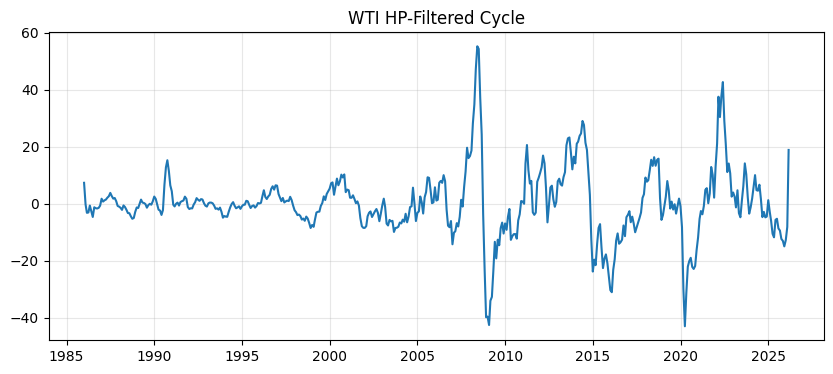

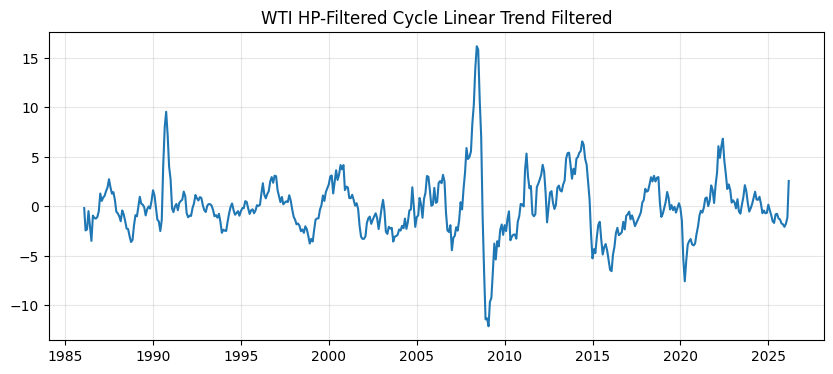

In [38]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
wti_cycle, wti_trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

wti_diff = (wti_cycle).diff().dropna()
wti_sigma = linear_vol_scale(wti_diff)

wti = wti_cycle/wti_sigma


plt.figure(figsize=(10,4))
plt.plot(wti_cycle)
plt.title("WTI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(wti)
plt.title("WTI HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_72024/1828479592.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


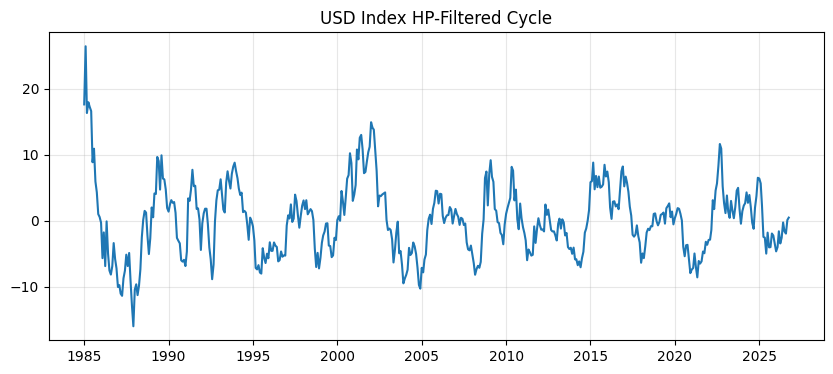

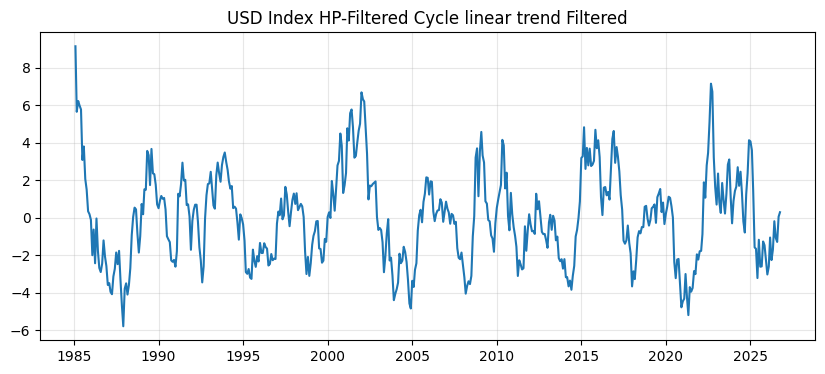

In [39]:
# -------------------------
# USD INDEX
# -------------------------
usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
usd_ind_original = usd_ind_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
usd_ind_cycle, trend = hpfilter(usd_ind_original, lamb=129600)

usd_ind_diff = (usd_ind_cycle).diff().dropna()
usd_ind_sigma = linear_vol_scale(usd_ind_diff)

usd_ind= usd_ind_cycle/usd_ind_sigma


plt.figure(figsize=(10,4))
plt.plot(usd_ind_cycle)
plt.title("USD Index HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(usd_ind)
plt.title("USD Index HP-Filtered Cycle linear trend Filtered")
plt.grid(alpha=0.3)
plt.show()

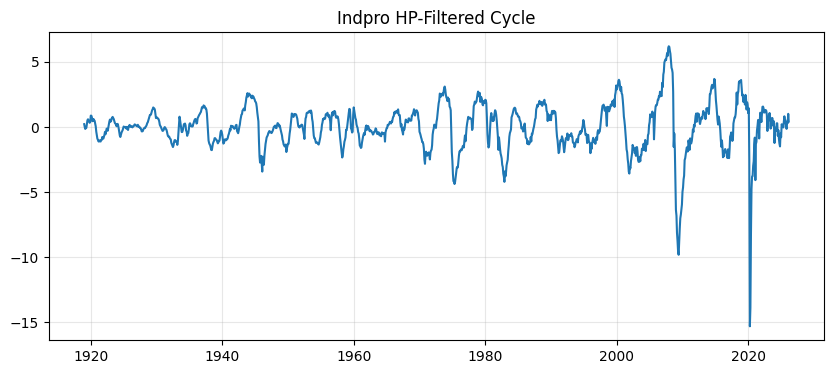

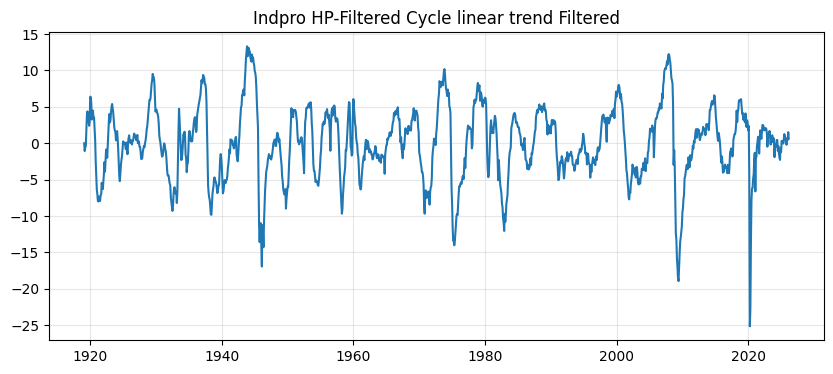

In [40]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter 
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle linear trend Filtered")
plt.grid(alpha=0.3)
plt.show()

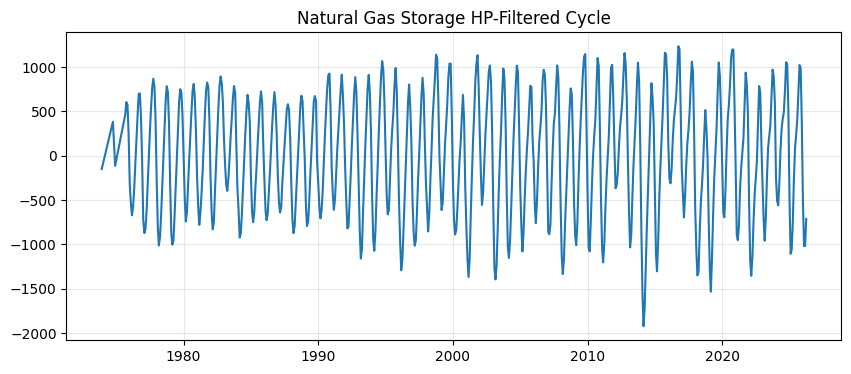

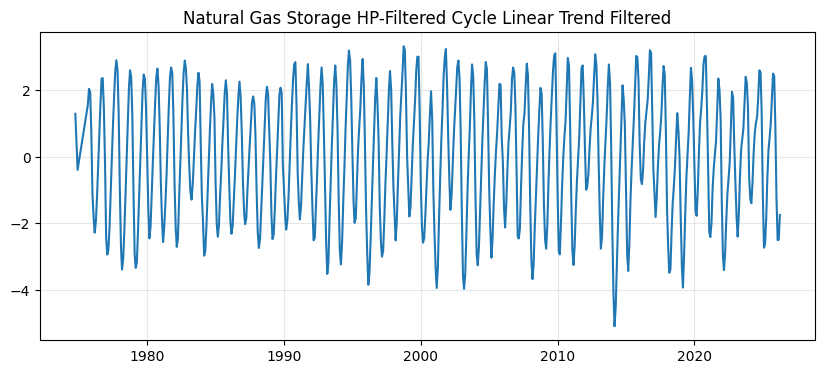

In [41]:
# -------------------------
# Natural Gas Storage
# -------------------------

df_ngas_storage = pd.read_excel(
    "Natural Gas Storage.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_ngas_storage["Date"] = pd.to_datetime(
    df_ngas_storage["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_storage["Date"] = df_ngas_storage["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_storage = df_ngas_storage.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------

df_ngas_storage=0.001*df_ngas_storage
ngas_storage_cycle, trend = hpfilter(
    df_ngas_storage["U.S. Natural Gas Underground Storage Volume (MMcf)"],
    lamb=129600
)

ngas_storage_diff = (ngas_storage_cycle).diff().dropna()
ngas_storage_sigma = linear_vol_scale(ngas_storage_diff)

ngas_storage = ngas_storage_cycle/ngas_storage_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_storage_cycle)
plt.title("Natural Gas Storage HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas_storage)
plt.title("Natural Gas Storage HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

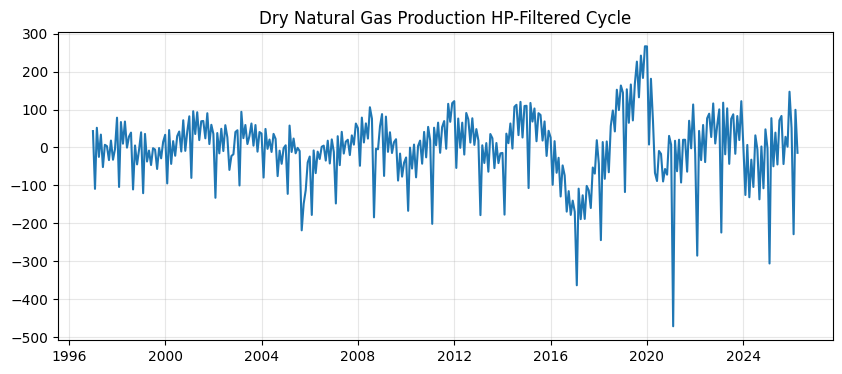

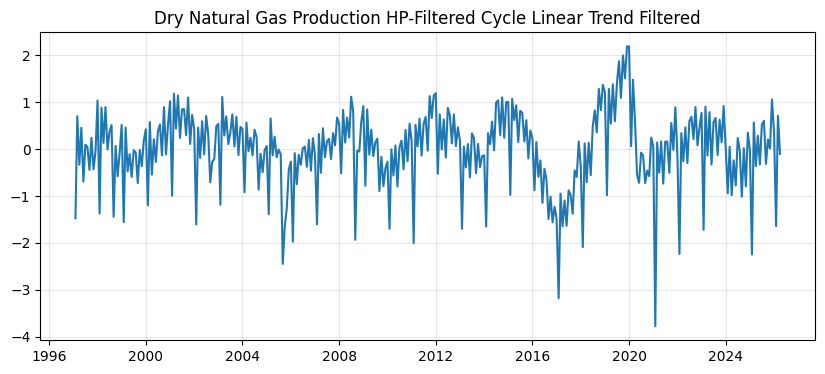

In [42]:
# -------------------------
# Dry Natural Gas Production
# -------------------------

df_ngas_prod = pd.read_excel(
    "Dry NGas Production.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_ngas_prod["Date"] = pd.to_datetime(
    df_ngas_prod["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_prod["Date"] = df_ngas_prod["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_prod = df_ngas_prod.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_ngas_prod=0.001*df_ngas_prod
ngas_prod_cycle, trend = hpfilter(
    df_ngas_prod["U.S. Dry Natural Gas Production (MMcf)"],
    lamb=129600
)


ngas_prod_diff = (ngas_prod_cycle).diff().dropna()
ngas_prod_sigma = linear_vol_scale(ngas_prod_diff)

ngas_prod = ngas_prod_cycle/ngas_prod_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_prod_cycle)
plt.title("Dry Natural Gas Production HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas_prod)
plt.title("Dry Natural Gas Production HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

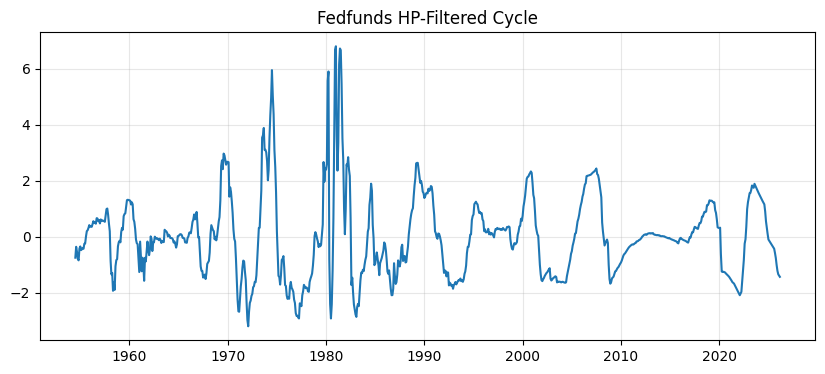

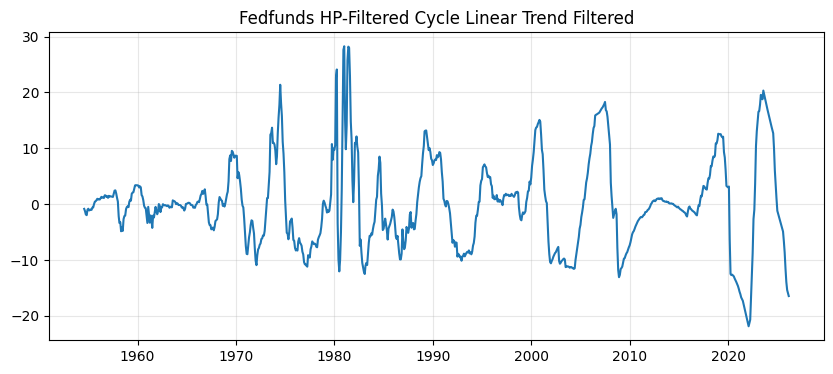

In [43]:
# -------------------------
# Fed Funds
# -------------------------
fedfunds_original = pd.read_csv("FEDFUNDS.csv", parse_dates=["observation_date"])
fedfunds_original = fedfunds_original.dropna().set_index("observation_date")

# -------------------------
# HP Filter 
# -------------------------
fedfunds_cycle, trend = hpfilter(fedfunds_original, lamb=129600)


fedfunds_diff = (fedfunds_cycle).diff().dropna()
fedfunds_sigma = linear_vol_scale(fedfunds_diff)

fedfunds = fedfunds_cycle/fedfunds_sigma


plt.figure(figsize=(10,4))
plt.plot(fedfunds_cycle)
plt.title("Fedfunds HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(fedfunds)
plt.title("Fedfunds HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_72024/482207131.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


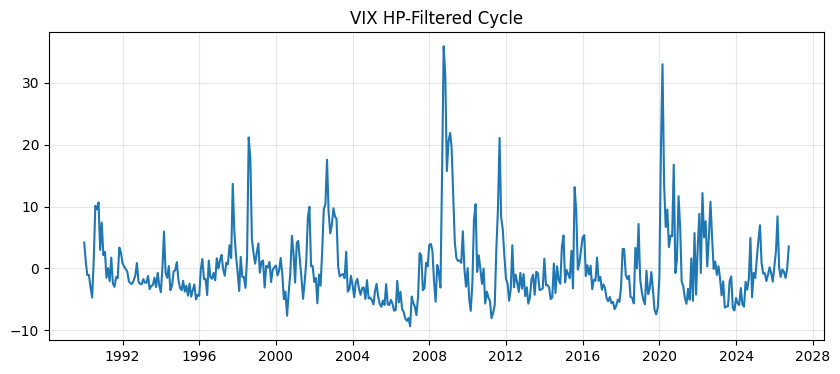

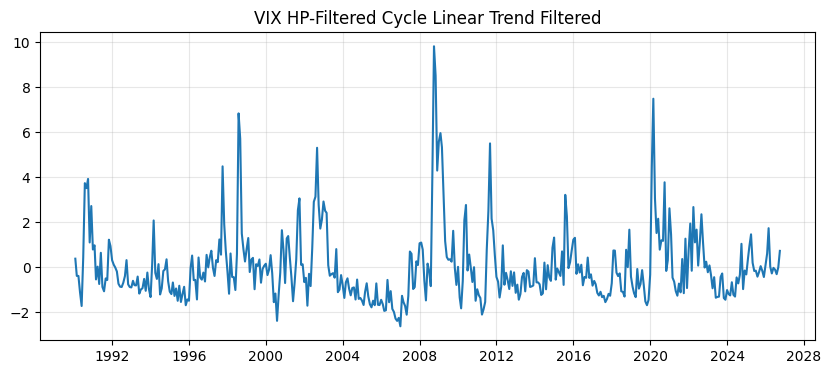

In [44]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
vix_cycle, trend = hpfilter(vix_original, lamb=129600)

vix_diff = (vix_cycle).diff().dropna()
vix_sigma = linear_vol_scale(vix_diff)

vix= vix_cycle/vix_sigma


plt.figure(figsize=(10,4))
plt.plot(vix_cycle)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(vix)
plt.title("VIX HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

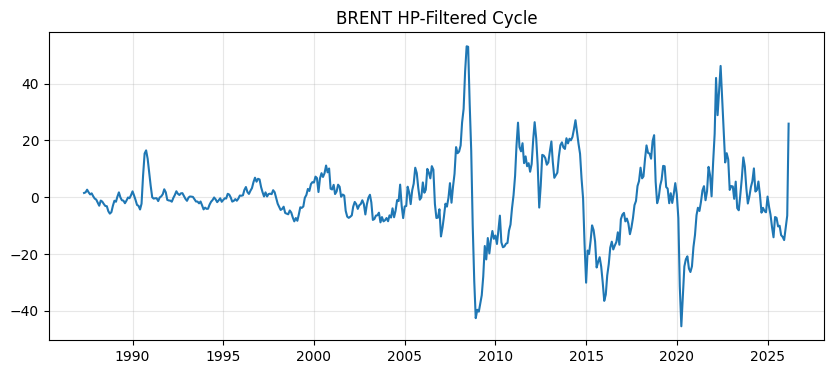

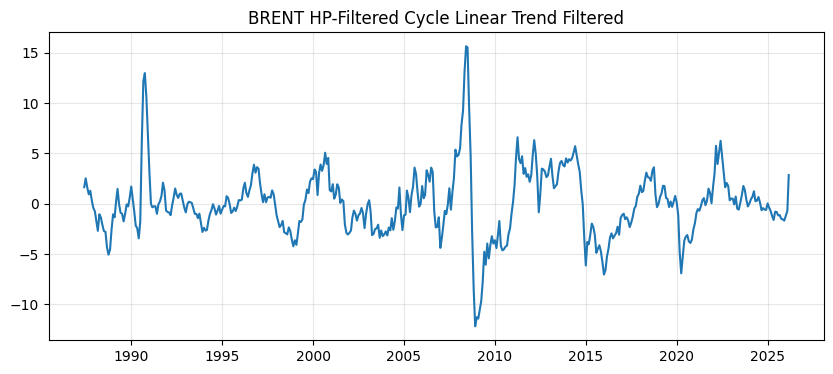

In [45]:
# -------------------------
# BRENT DATA
# -------------------------
df_brent = pd.read_csv("MCOILBRENTEU.csv", parse_dates=["observation_date"])
df_brent = df_brent.dropna().set_index("observation_date")

# HP filter
brent_cycle, brent_trend = hpfilter(df_brent["MCOILBRENTEU"], lamb=129600)

brent_diff = (brent_cycle).diff().dropna()
brent_sigma = linear_vol_scale(brent_diff)

brent= brent_cycle/brent_sigma


plt.figure(figsize=(10,4))
plt.plot(brent_cycle)
plt.title("BRENT HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(brent)
plt.title("BRENT HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

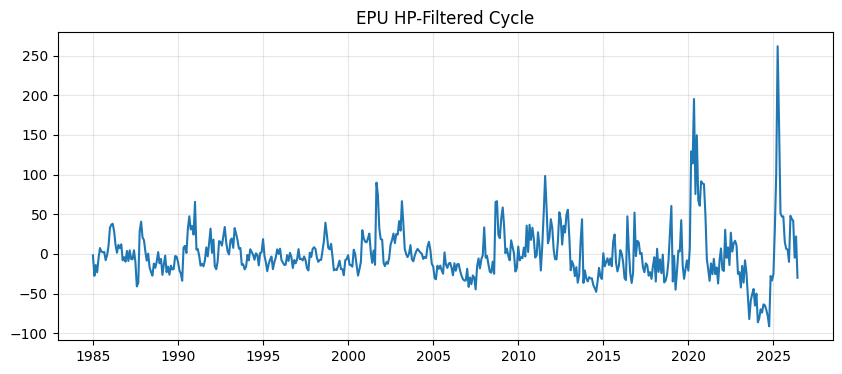

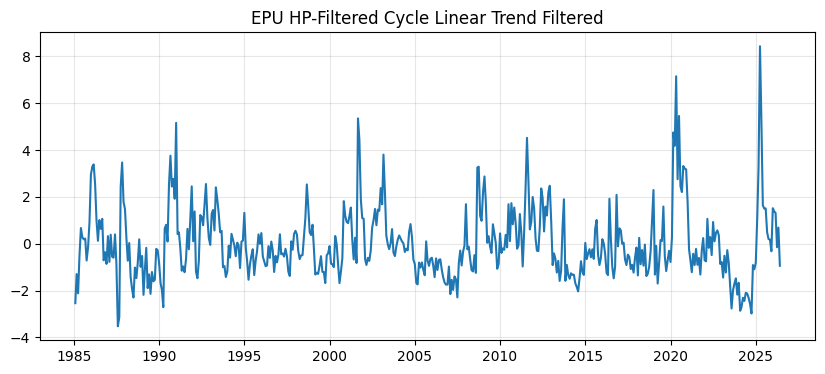

In [46]:
# -------------------------
# Economic Policy Uncertainty US
# -------------------------
df_epu = pd.read_csv("USEPUINDXM.csv", parse_dates=["observation_date"])
df_epu = df_epu.dropna().set_index("observation_date")


# HP filter
epu_cycle , trend = hpfilter(df_epu["USEPUINDXM"], lamb=129600)

epu_diff = (epu_cycle).diff().dropna()
epu_sigma = linear_vol_scale(epu_diff)

epu= epu_cycle/epu_sigma


plt.figure(figsize=(10,4))
plt.plot(epu_cycle)
plt.title("EPU HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(epu)
plt.title("EPU HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

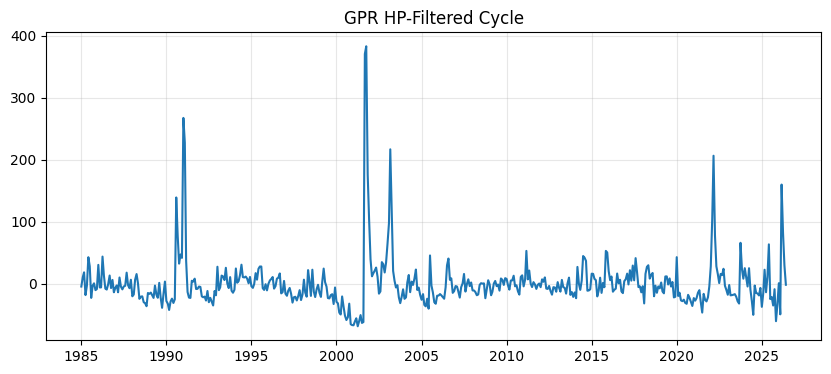

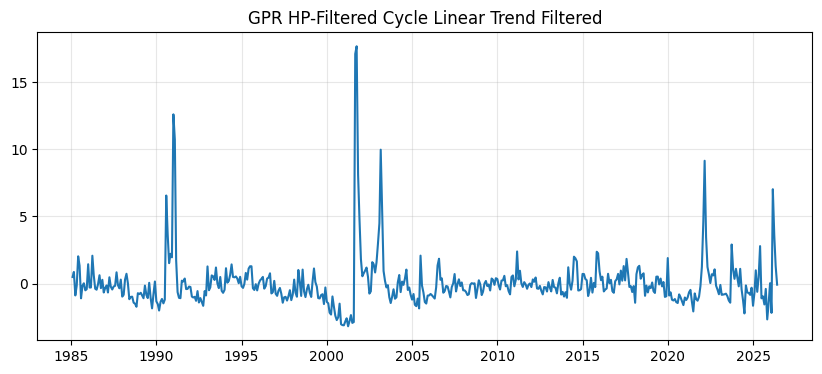

In [47]:
# -------------------------
# GPR
# -------------------------
df = pd.read_excel("GPR.xls", usecols=["month", "GPR"])

# Convert Month column to datetime
df["month"] = pd.to_datetime(df["month"])

# Set Month as index
df = df.set_index("month")

# Extract GPR series
gpr_original = df["GPR"].dropna()

# -------------------------
# HP Filter
# -------------------------
gpr_cycle, gpr_trend = hpfilter(gpr_original, lamb=129600)

gpr_diff = (gpr_cycle).diff().dropna()
gpr_sigma = linear_vol_scale(gpr_diff)

gpr = gpr_cycle/gpr_sigma


plt.figure(figsize=(10,4))
plt.plot(gpr_cycle)
plt.title("GPR HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(gpr)
plt.title("GPR HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

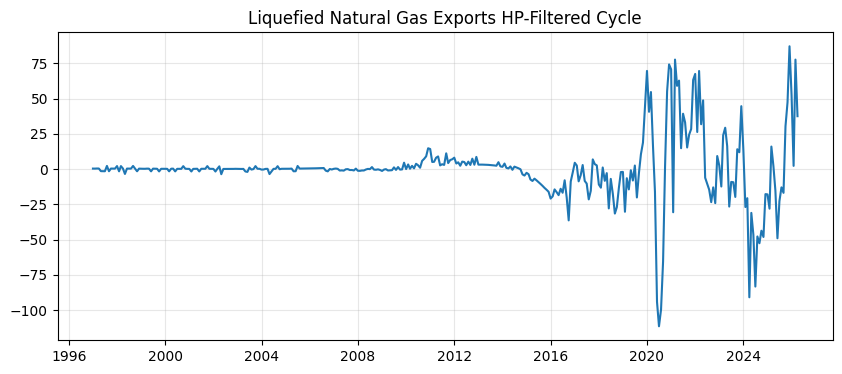

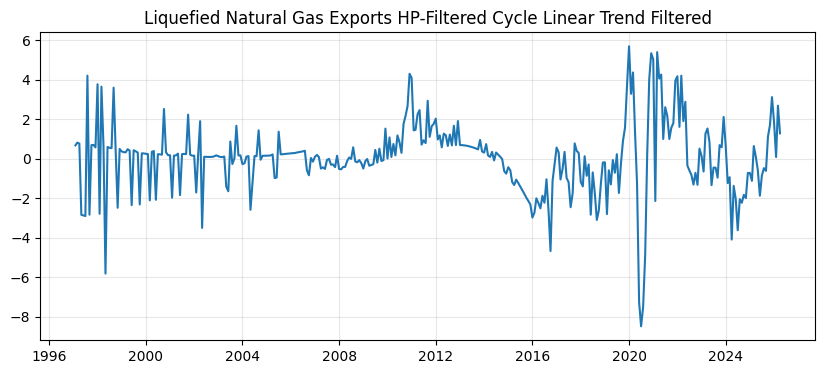

In [48]:
# -------------------------
# LNGas Exports
# -------------------------

df_ngas_exports = pd.read_excel(
    "LNG Exports.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column
df_ngas_exports["Date"] = pd.to_datetime(
    df_ngas_exports["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_exports["Date"] = df_ngas_exports["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_exports = df_ngas_exports.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_ngas_exports=0.001*df_ngas_exports
ngas_exports_cycle, trend = hpfilter(
    df_ngas_exports["Liquefied U.S. Natural Gas Exports (MMcf)"],
    lamb=129600
)

ngas_exports_diff = (ngas_exports_cycle).diff().dropna()
ngas_exports_sigma = linear_vol_scale(ngas_exports_diff)

ngas_exports = ngas_exports_cycle/ngas_exports_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_exports_cycle)
plt.title("Liquefied Natural Gas Exports HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas_exports)
plt.title("Liquefied Natural Gas Exports HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

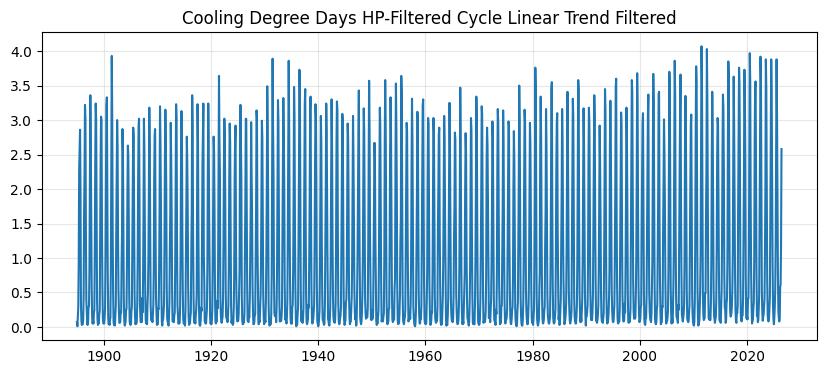

In [49]:
# -------------------------
# Cooling Degree Days
# -------------------------
df_cdd = pd.read_csv(
    "CDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_cdd = df_cdd.set_index("Date").dropna()

cdd=0.01*df_cdd



plt.figure(figsize=(10,4))
plt.plot(cdd)
plt.title("Cooling Degree Days HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

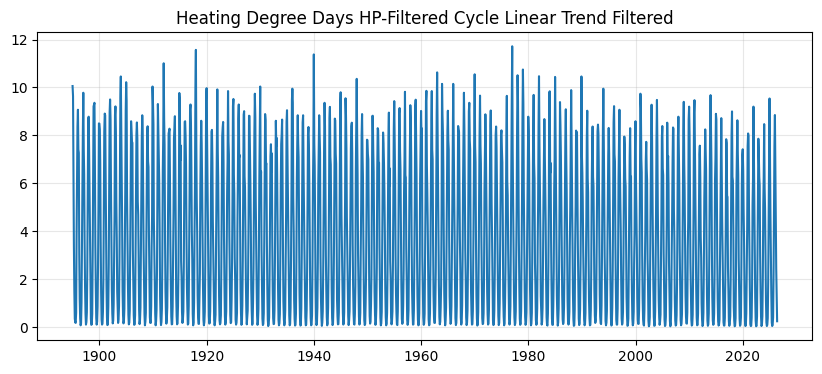

In [50]:
# -------------------------
# Heating Degree Days
# -------------------------
df_hdd = pd.read_csv(
    "HDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_hdd = df_hdd.set_index("Date").dropna()

hdd=0.01*df_hdd


plt.figure(figsize=(10,4))
plt.plot(hdd)
plt.title("Heating Degree Days HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_72024/696354010.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


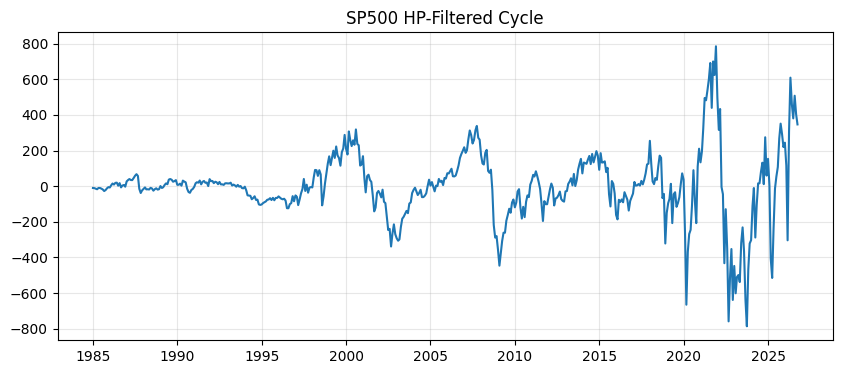

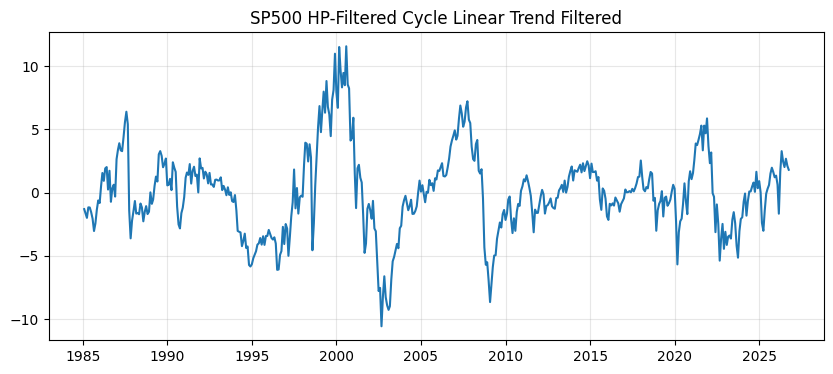

In [51]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter
sp500_cycle, trend = hpfilter(sp500_original, lamb=129600)

sp500_diff = (sp500_cycle).diff().dropna()
sp500_sigma = linear_vol_scale(sp500_diff)

sp500= sp500_cycle/sp500_sigma


plt.figure(figsize=(10,4))
plt.plot(sp500_cycle)
plt.title("SP500 HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 HP-Filtered Cycle Linear Trend Filtered")
plt.grid(alpha=0.3)
plt.show()

In [52]:
# Data and Parameters 
df = pd.concat(
    [
        df_ngas["gas_scaled_cycle"], wti, usd_ind, indpro, ngas_storage, ngas_prod, fedfunds, vix, brent, epu, gpr, ngas_exports, hdd, cdd, sp500
    ],
    axis=1
).dropna()

df.columns = ["gas_scaled_cycle",  "wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "ngas_exports", "hdd", "cdd", "sp500"]
df = df.sort_index()


start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()


y = df["gas_scaled_cycle"].values
X = df[["wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "ngas_exports", "hdd", "cdd", "sp500"]].values

var = ["wti", "usd_ind", "indpro", "ngas_storage", "ngas_prod", "fedfunds", "vix", "brent", "epu", "gpr", "ngas_exports", "hdd", "cdd", "sp500"]

t0=len(y)-3 # point to calculate predictive density

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

#Define Grid for all experiments
grid_min=-50
grid_max=50
ngrid=3000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=3
values=30

prominence = 0.01

y_limits=(-10, 15)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


In [53]:
#Import pickle with PSY

import pickle

with open("psy_ngas.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -499.50269554935034

Estimated parameters:
phi             =     0.2449 (0.0262)
psi             =     0.8005 (0.0219)
sigma           =     0.4236 (0.0304)

Hessian condition number:
2.3192499361760976

Eigenvalues of Hessian:
[2472.9106178  1345.91612008 1066.25447272]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -499.502696
AIC:            1005.005391
BIC:            1016.561999
R^2:            0.682785

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 15.882478, p-value = 6.73998e-05
    lag  5: statistic = 28.527135, p-value = 2.87041e-05
    lag 10: statistic = 39.253775, p-value = 2.29175e-05
    lag 20: statistic = 44.511214, p-value = 0.00128481

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 24.323730, p-value = 8.14297e-07
    la

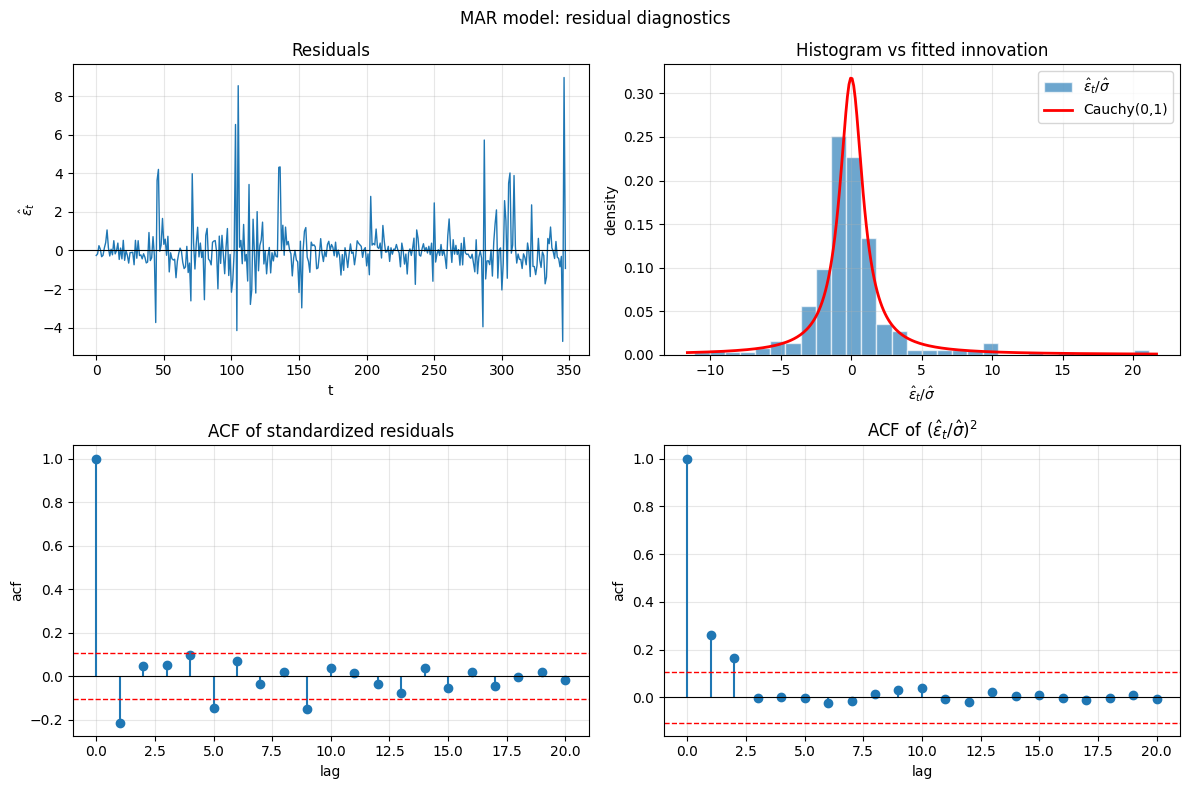

In [54]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

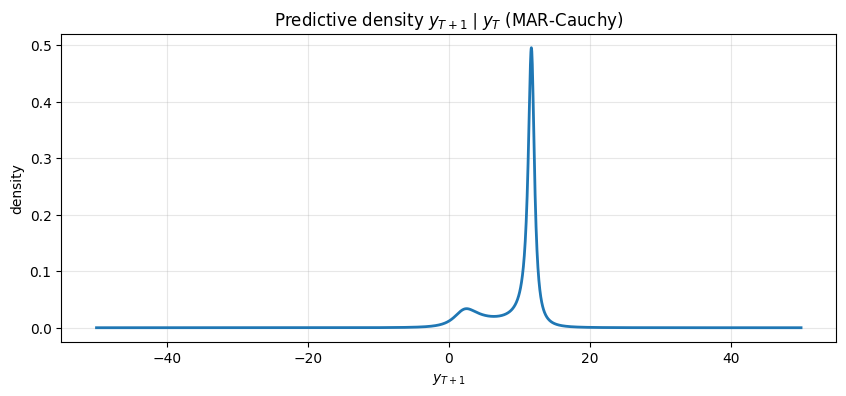

In [55]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

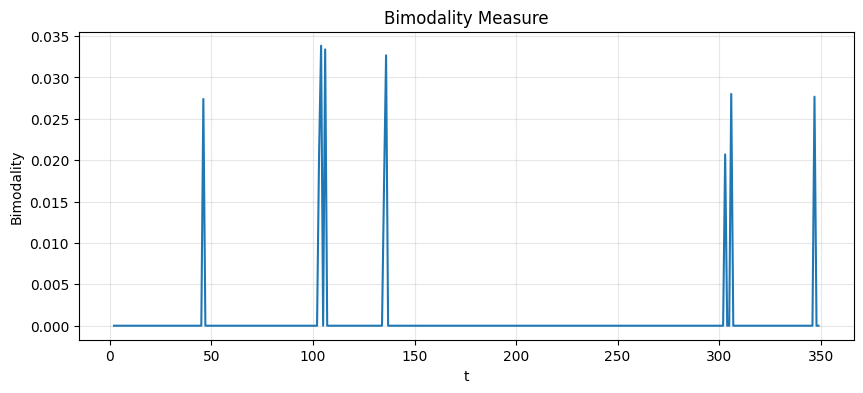

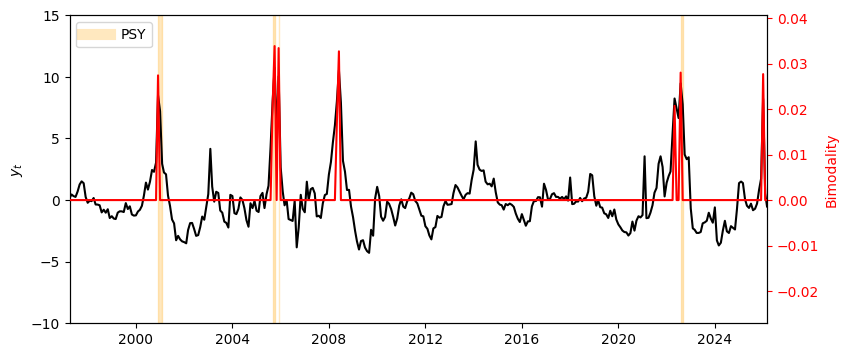

In [56]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -485.38052793146085

Estimated parameters:
phi             =     0.2493 (0.0432)
psi             =     0.7290 (0.0572)
beta_wti        =     0.0464 (0.0498)
beta_usd_ind    =     0.0185 (0.0210)
beta_indpro     =     0.0323 (0.0113)
beta_ngas_storage =    -0.0087 (0.0217)
beta_ngas_prod  =    -0.0258 (0.0434)
beta_fedfunds   =    -0.0132 (0.0074)
beta_vix        =    -0.0071 (0.0292)
beta_brent      =    -0.0270 (0.0438)
beta_epu        =     0.0283 (0.0252)
beta_gpr        =    -0.0293 (0.0286)
beta_ngas_exports =    -0.0318 (0.0215)
beta_hdd        =    -0.0227 (0.0110)
beta_cdd        =    -0.0308 (0.0208)
beta_sp500      =    -0.0260 (0.0127)
sigma           =     0.4037 (0.0310)

Hessian condition number:
474.9282297943245

Eigenvalues of Hessian:
[90693.33559264 26505.98833394 20969.75167454 11104.68425528
  6335.93480939  4639.47069777  3480.02764514  2687.51304167
  2450.82952894  1969.23234331   190.96219155   258.87887701
  1519.7256

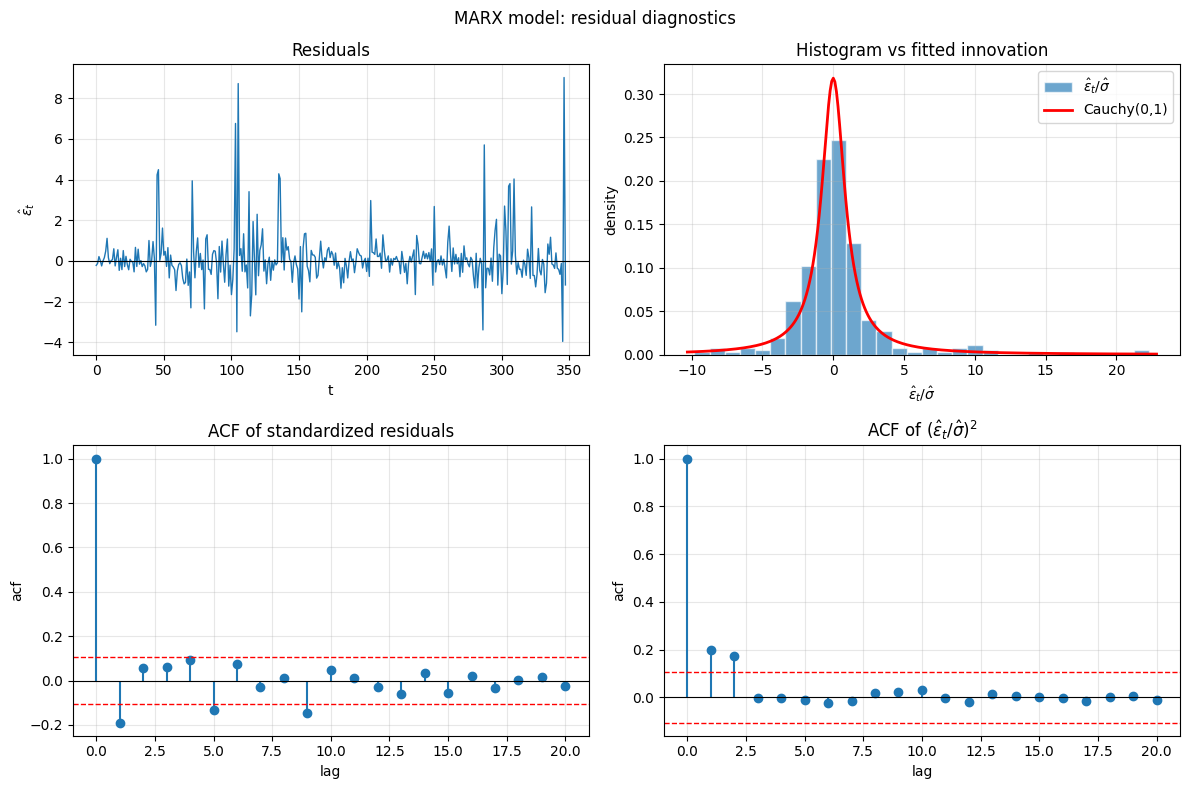

In [57]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_wti", "beta_usd_ind", "beta_indpro", "beta_ngas_storage", "beta_ngas_prod", "beta_fedfunds", "beta_vix", "beta_brent", "beta_epu", "beta_gpr", "beta_ngas_exports", "beta_hdd", "beta_cdd", "beta_sp500", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

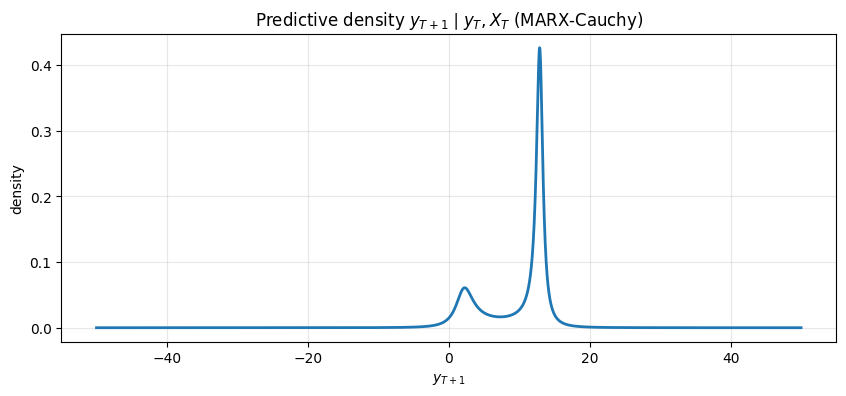

In [58]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

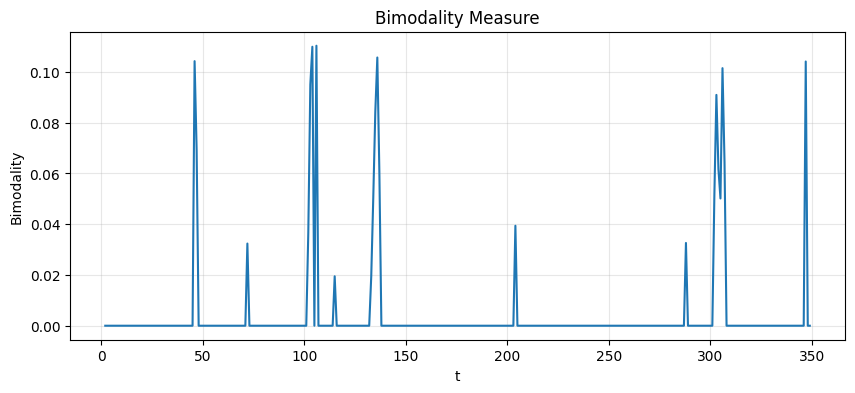

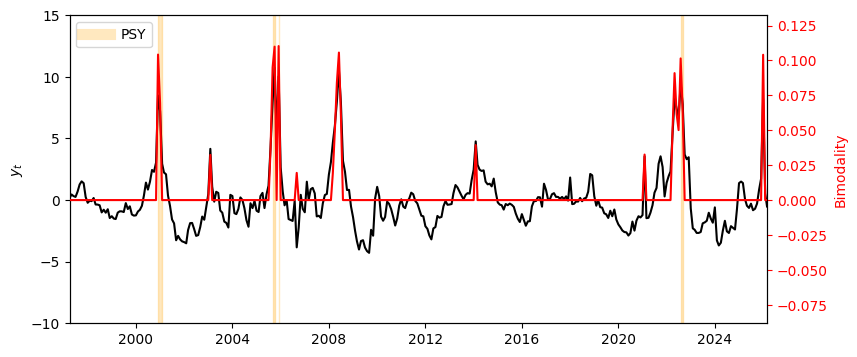

In [59]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -489.95525752865217

Estimated parameters:
phi             =     0.2242 (0.0351)
psi             =     0.7909 (0.0243)
sigma           =     0.5536 (0.0457)
nu              =     2.0100 (0.3009)

Hessian condition number:
191.91610065235838

Eigenvalues of Hessian:
[2097.06591543  753.08778715  884.533825     10.92699314]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -489.955258
AIC:            987.910515
BIC:            1003.319325
R^2:            0.686057

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 11.928529, p-value = 0.000552808
    lag  5: statistic = 24.682376, p-value = 0.00016045
    lag 10: statistic = 35.121698, p-value = 0.000119032
    lag 20: statistic = 40.483838, p-value = 0.00433681

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: s

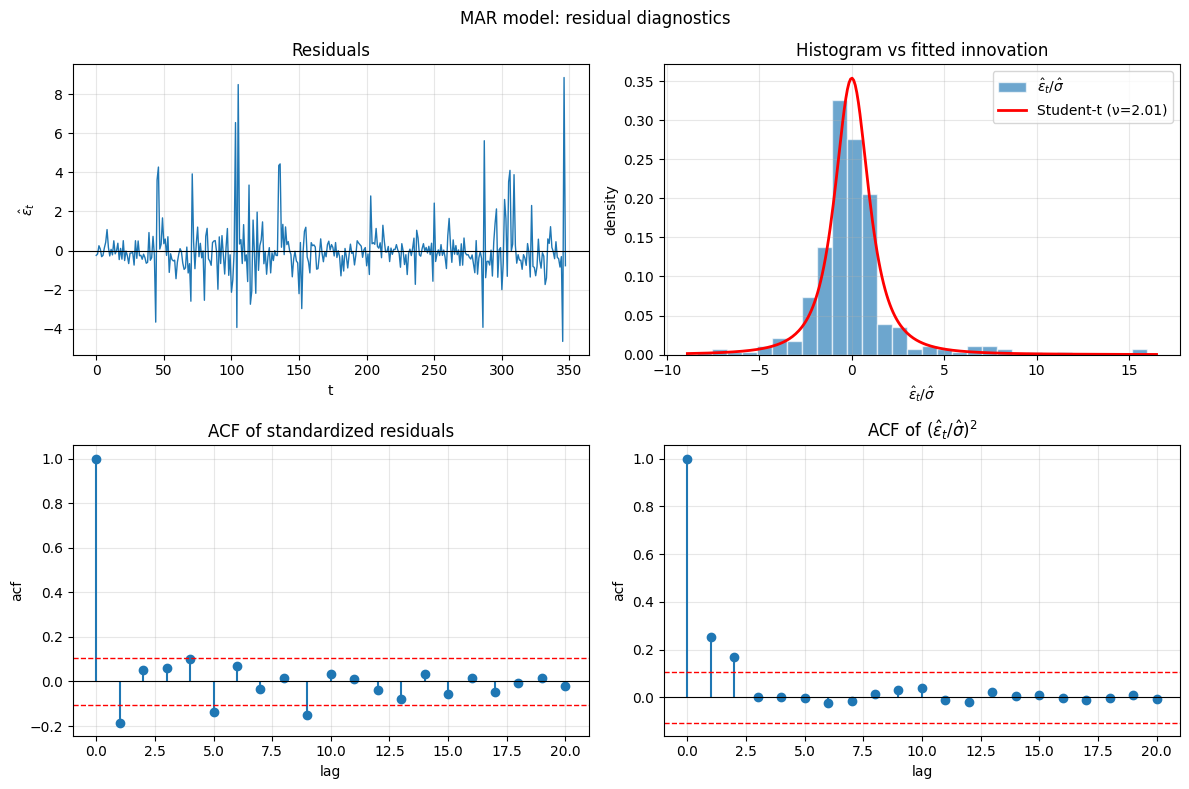

In [60]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

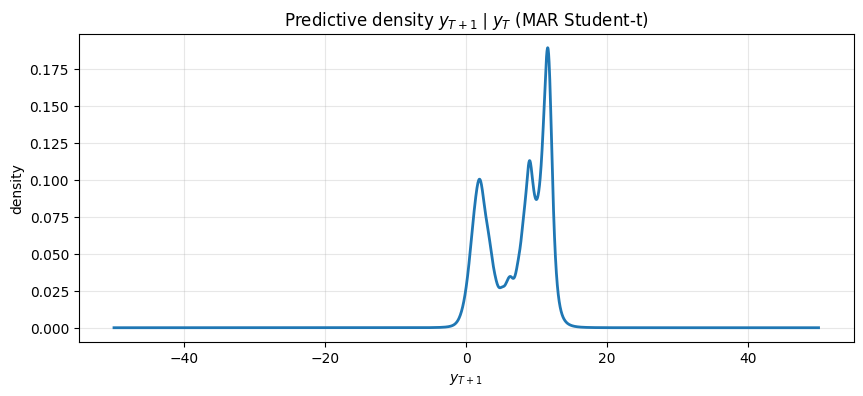

In [61]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

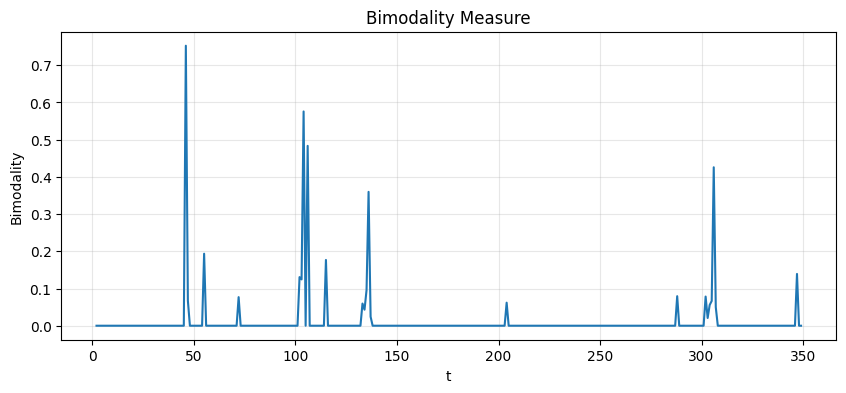

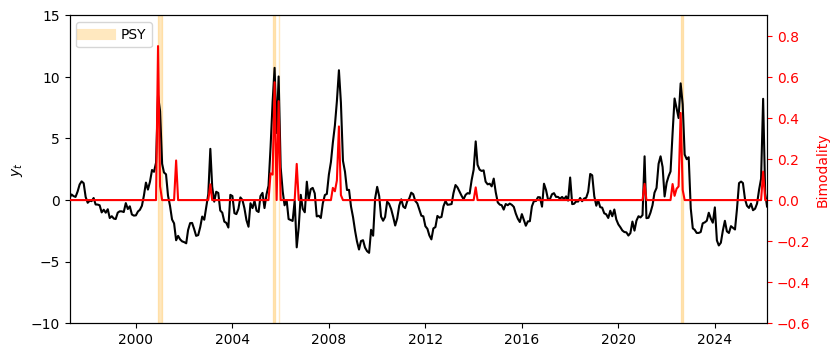

In [62]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -473.3548751936877

Estimated parameters:
phi             =     0.2689 (0.0418)
psi             =     0.6281 (0.0489)
beta_wti        =     0.1055 (0.0535)
beta_usd_ind    =     0.0309 (0.0200)
beta_indpro     =     0.0425 (0.0139)
beta_ngas_storage =    -0.0266 (0.0223)
beta_ngas_prod  =    -0.0379 (0.0512)
beta_fedfunds   =    -0.0217 (0.0081)
beta_vix        =     0.0121 (0.0325)
beta_brent      =    -0.0499 (0.0490)
beta_epu        =     0.0316 (0.0304)
beta_gpr        =    -0.0589 (0.0247)
beta_ngas_exports =    -0.0372 (0.0240)
beta_hdd        =    -0.0282 (0.0109)
beta_cdd        =    -0.0512 (0.0228)
beta_sp500      =    -0.0214 (0.0159)
sigma           =     0.5406 (0.0429)
nu              =     2.0100 (0.2894)

Hessian condition number:
5392.882375663212

Eigenvalues of Hessian:
[6.36538924e+04 2.23431118e+04 1.40962236e+04 7.61278674e+03
 4.08432087e+03 3.53388096e+03 2.69494149e+03 2.32828701e+03
 1.84822562e+03 1.18033155e+01 1.95

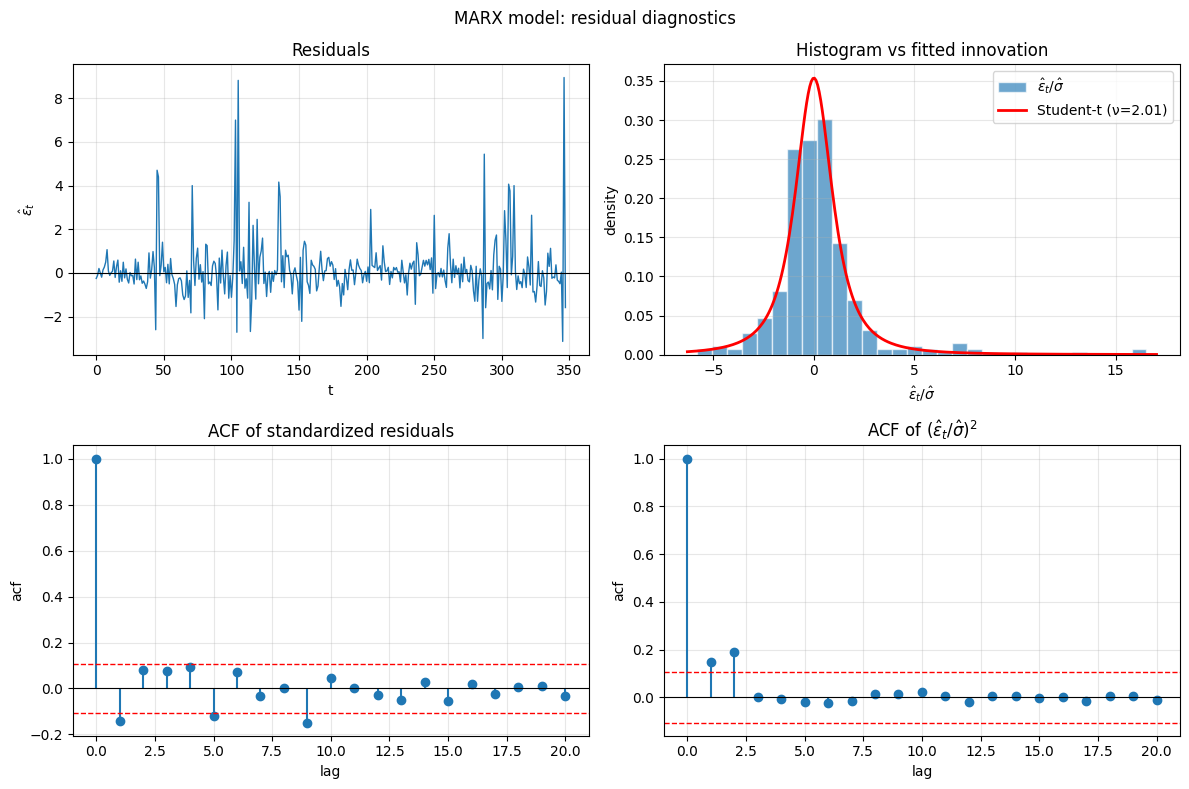

In [63]:
param_names = [ "phi", "psi", "beta_wti", "beta_usd_ind", "beta_indpro", "beta_ngas_storage", "beta_ngas_prod", "beta_fedfunds", "beta_vix", "beta_brent", "beta_epu", "beta_gpr", "beta_ngas_exports", "beta_hdd", "beta_cdd", "beta_sp500", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

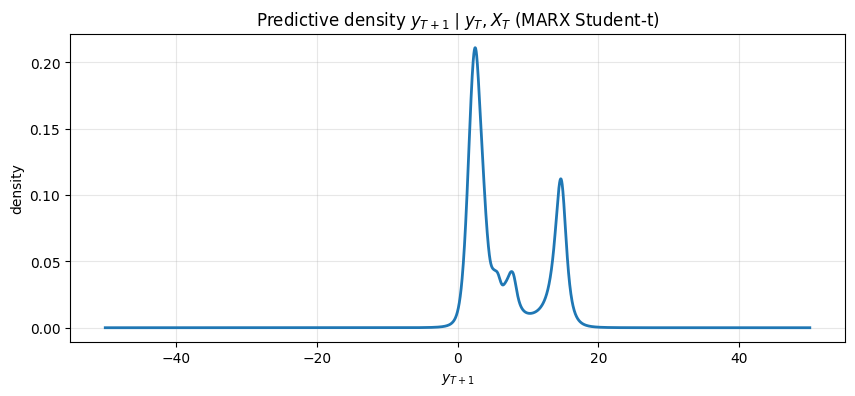

In [64]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

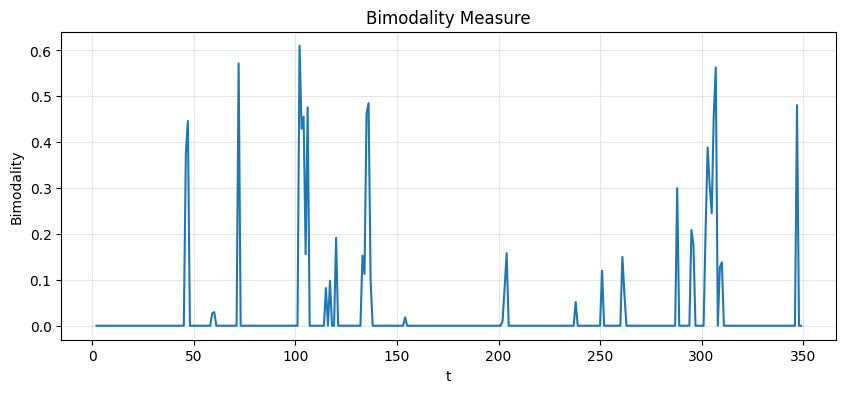

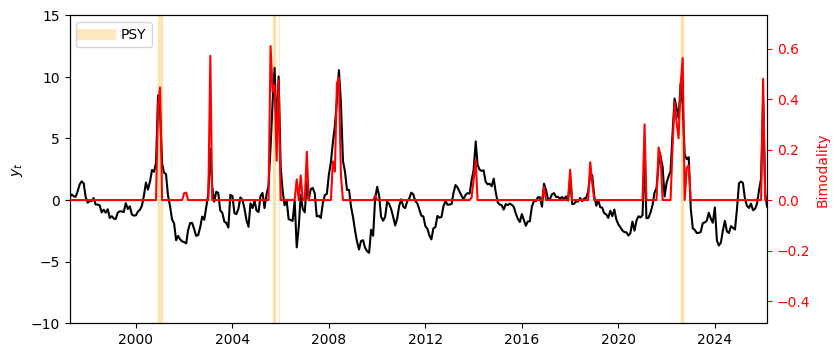

In [65]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)
